# LSTM forecasting: architecture, training and controlled experiments

## 1. Research objective and motivation

Can a small nonlinear sequence model improve next-session NVIDIA closing-price forecasts over persistence and ARIMA? Persistence carries the latest price forward; ARIMA estimates linear statistical dependencies. An LSTM learns nonlinear functions of an ordered sequence, but greater flexibility does not guarantee useful out-of-sample information.

The target remains **Yahoo split-adjusted NVDA Close in USD**, one trading session after the forecast origin. Each input contains the preceding **30 observed sessions**, including the origin. Prices are retrospective vendor histories, not original contemporaneous quotes or a trading-profit backtest. Volume is excluded.

| Stage | Fitting targets | Evaluation targets | Purpose |
|---|---|---|---|
| Internal selection | 2015–2021, after the initial lookback | 2022 | Early stopping and four-configuration comparison |
| Selected-model fit | 2015–2022, after the initial lookback | 2023–2024 | Fixed-epoch comparison with naïve and ARIMA |
| Reserved final test | No access here | 2025 | Only after a separately approved methodology freeze |

We evaluate **MAE and RMSE in USD**. This notebook executes the actual data, preprocessing, model-loading, inference, selection and metric functions. The original 12 selection runs and three final fits supply training evidence; execution performs **no optimiser updates or additional model fits**. Its saved outputs form a self-contained demonstration. Raw snapshots and checkpoints are required to rerun it; see the [environment instructions](../README.md#installation), [design](../docs/MILESTONE_5_DESIGN.md) and [experiment record](../docs/MILESTONE_5.md).

In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import inspect
import json
import math
import runpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown, Code

from market_forecasting.preprocessing import (
    Standardisation, prepare_residual_data, reconstruct_prices,
)
from market_forecasting.dataset import error_metrics, naive_predictions
from market_forecasting.lstm import (
    configure_runtime, build_model, predict_standardised, train_model,
    EarlyStopState, choose_configuration,
)
configure_runtime()  # Must precede TensorFlow tensor operations in a fresh kernel.
import tensorflow as tf

ROOT = Path.cwd() if (Path.cwd() / "configs/nvda.json").exists() else Path.cwd().parent
BASE = ROOT / "artifacts/lstm_v1"
config = json.loads((ROOT / "configs/nvda.json").read_text())
search = json.loads((ROOT / "configs/lstm_search_v1.json").read_text())
selected = json.loads((ROOT / "configs/lstm_selected_v1.json").read_text())
results = json.loads((ROOT / "docs/lstm_results_v1.json").read_text())
internal_runs = json.loads((BASE / "selection/runs.json").read_text())
final_runs = json.loads((BASE / "final/runs.json").read_text())
assert len(internal_runs) == 12 and len(final_runs) == 3
assert results["attempts"] == 15 and results["failed_attempts"] == 0
assert not results["test_evaluated"]
assert all(r["status"] == "complete" and not r["test_evaluated"] for r in internal_runs + final_runs)
assert hashlib.sha256((ROOT / "configs/lstm_search_v1.json").read_bytes()).hexdigest() == selected["search_sha256"]

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
BLUE, ORANGE, GREEN, RED = "#2563eb", "#c56b12", "#168269", "#b83a48"
ARIMA_COLOR = "#7c3aed"
SEEDS = search["seeds"]
SEED_COLORS = dict(zip(SEEDS, [BLUE, ORANGE, GREEN]))
MODEL_COLORS = {"Naive": "#64748b", "ARIMA": ARIMA_COLOR,
                **{f"LSTM seed {seed}": color for seed, color in SEED_COLORS.items()}}
pd.options.display.float_format = "{:,.6f}".format

# run_path imports the existing runner without invoking its command-line main().
runner = runpy.run_path(str(ROOT / "scripts/run_lstm_experiments.py"))
load_stage = runner["load_stage"]
print(f"Recorded fits: {len(internal_runs)} selection + {len(final_runs)} final; no training in this notebook.")
print(f"Runtime: TensorFlow {tf.__version__}; NumPy {np.__version__}; CPU deterministic operations enabled.")

Recorded fits: 12 selection + 3 final; no training in this notebook.
Runtime: TensorFlow 2.21.0; NumPy 2.5.4; CPU deterministic operations enabled.


## 2. Neural-network foundations

A neuron combines inputs using learned weights and a bias, then applies an activation:
\[
a=\mathbf{w}^{\mathsf T}\mathbf{x}+b,\qquad h=\tanh(a).
\]
Weights control how inputs contribute; the bias shifts the activation. Nonlinear activation allows compositions that cannot be expressed as one linear map. Trainable parameters are these learned numerical values; hyperparameters such as unit count and learning rate determine the learning procedure.

A forward pass maps inputs to a prediction. For a single illustrative observation, squared error is \(L=(h-y)^2\), and
\[
\frac{\partial L}{\partial w_j}=2(h-y)(1-h^2)x_j.
\]
Gradient descent moves parameters against this gradient: \(w_j^{\mathrm{new}}=w_j-\eta\,\partial L/\partial w_j\). The following **toy calculation**, not an NVDA training run, verifies the derivative with TensorFlow automatic differentiation. No saved-model weight is updated. In our forecasting network, recurrent layers form a sequential representation and a linear Dense layer outputs a standardised dollar correction.

In [2]:
x_toy = tf.constant([.2, -.4, .8], dtype=tf.float32)
w_toy = tf.constant([.5, -.25, .1], dtype=tf.float32)
b_toy, target_toy = .05, .15
with tf.GradientTape() as tape:
    tape.watch(w_toy)
    activation_toy = tf.tanh(tf.reduce_sum(w_toy * x_toy) + b_toy)
    loss_toy = (activation_toy - target_toy) ** 2
gradient_toy = tape.gradient(loss_toy, w_toy).numpy()
analytic_toy = 2 * (float(activation_toy) - target_toy) * (1 - float(activation_toy) ** 2) * x_toy.numpy()
np.testing.assert_allclose(gradient_toy, analytic_toy, rtol=1e-6)
display(pd.DataFrame({"input": x_toy.numpy(), "weight": w_toy.numpy(),
                      "gradient": gradient_toy,
                      "illustrative next weight (eta=.01)": w_toy.numpy() - .01 * gradient_toy}))
print(f"Toy activation={float(activation_toy):.6f}, squared error={float(loss_toy):.6f}.")

,input,weight,gradient,illustrative next weight (eta=.01)
0,0.200000,0.500000,0.060569,0.499394
1,-0.400000,-0.250000,-0.121139,-0.248789
2,0.800000,0.100000,0.242277,0.097577


Toy activation=0.318521, squared error=0.028399.


## 3. Recurrent networks and LSTM memory

An ordinary RNN processes one session at a time, updating a hidden state, for example \(h_t=\tanh(W_xx_t+W_hh_{t-1}+b)\). Backpropagation through many repeated transformations can shrink gradients, making long-range learning difficult; gradients can also grow. An LSTM adds a gated cell-state path that can preserve information and gradient flow. It does not eliminate optimisation difficulties or guarantee long-term financial predictability.

For the implementation's default sigmoid gates and tanh candidate, with elementwise multiplication \(\odot\):
\[
\begin{aligned}
f_t&=\sigma(W_fx_t+U_fh_{t-1}+b_f) &&\text{forget: retain previous memory},\\
i_t&=\sigma(W_ix_t+U_ih_{t-1}+b_i) &&\text{input: admit new information},\\
\widetilde c_t&=\tanh(W_cx_t+U_ch_{t-1}+b_c) &&\text{candidate: proposed memory},\\
c_t&=f_t\odot c_{t-1}+i_t\odot\widetilde c_t &&\text{cell: combine retained and new memory},\\
o_t&=\sigma(W_ox_t+U_oh_{t-1}+b_o) &&\text{output: expose memory},\\
h_t&=o_t\odot\tanh(c_t) &&\text{hidden: output representation}.
\end{aligned}
\]
Here \(x_t\) has one component (standardised Close), while each gate, \(c_t\) and \(h_t\) has **16 components**. A unit is a coordinate in this learned state, not a separate day or a named financial indicator. The same weights are reused for all 30 timesteps. The final hidden vector feeds Dense(1). This model is **stateless between windows**: hidden/cell states start at zero for each sample; temporal memory operates within each window. The batch dimension does not connect different samples. See the [Keras LSTM contract](https://keras.io/api/layers/recurrent_layers/lstm/).

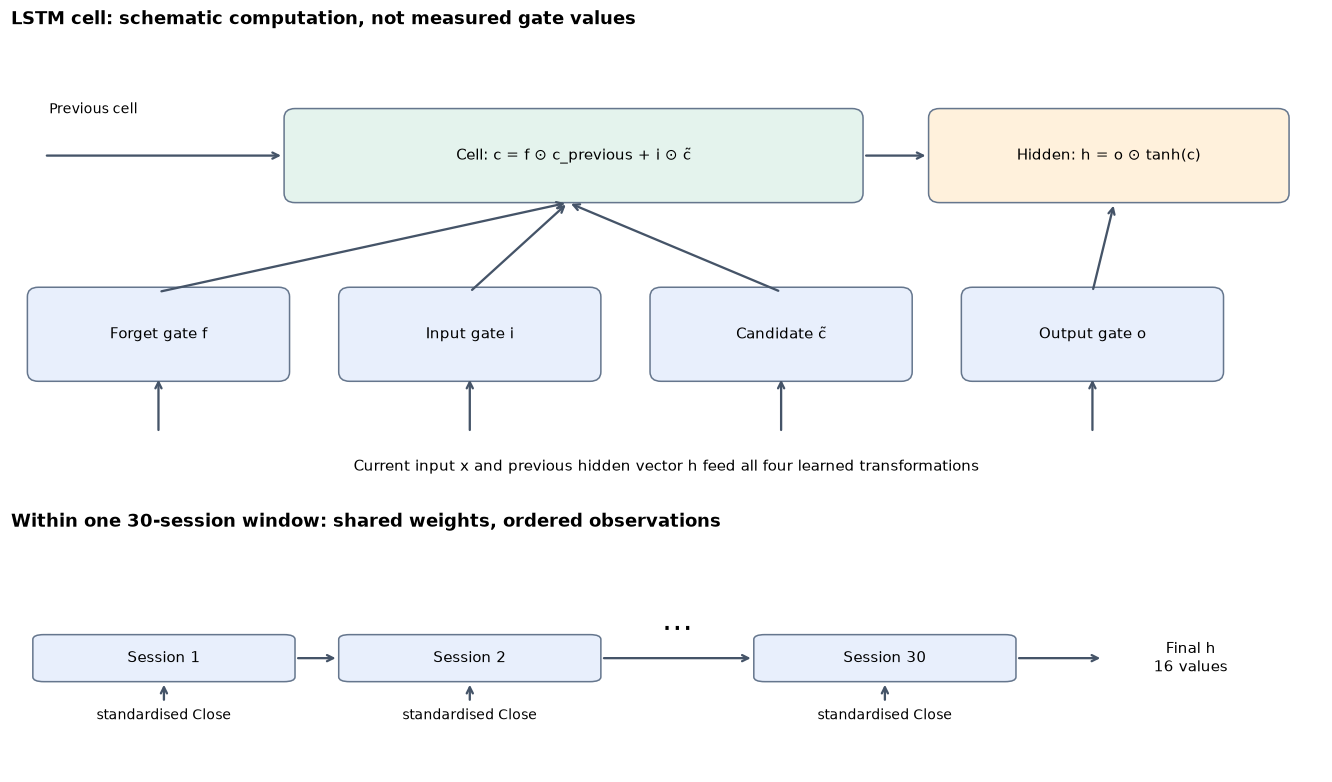

,retained memory,new contribution,updated cell,hidden output
0,0.320000,-0.050000,0.270000,0.158175


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained",
                         gridspec_kw={"height_ratios": [2, 1]})
for ax in axes:
    ax.set(xlim=(0, 12), ylim=(0, 5)); ax.axis("off")

def box(ax, xy, text, width=2.2, color="#e8effc"):
    ax.add_patch(FancyBboxPatch(xy, width, .8, boxstyle="round,pad=.1",
                               facecolor=color, edgecolor="#65768d"))
    ax.text(xy[0]+width/2, xy[1]+.4, text, ha="center", va="center", fontsize=10)

def arrow(ax, start, end):
    ax.annotate("", xy=end, xytext=start,
                arrowprops={"arrowstyle": "->", "color": "#455468", "lw": 1.5})

ax = axes[0]
ax.set_title("LSTM cell: schematic computation, not measured gate values", loc="left", weight="bold")
for position, label in zip([.25, 3.1, 5.95, 8.8], ["Forget gate f", "Input gate i", "Candidate c̃", "Output gate o"]):
    box(ax, (position, 1.4), label)
ax.text(6, .35, "Current input x and previous hidden vector h feed all four learned transformations",
        ha="center", fontsize=10)
for position in [1.35, 4.2, 7.05, 9.9]: arrow(ax, (position, .75), (position, 1.35))
box(ax, (2.6, 3.3), "Cell: c = f ⊙ c_previous + i ⊙ c̃", width=5.1, color="#e4f3ed")
box(ax, (8.5, 3.3), "Hidden: h = o ⊙ tanh(c)", width=3.1, color="#fff1dc")
arrow(ax, (.3, 3.7), (2.5, 3.7)); ax.text(.35, 4.15, "Previous cell", fontsize=9)
for start in [(1.35, 2.25), (4.2, 2.25), (7.05, 2.25)]: arrow(ax, start, (5.1, 3.2))
arrow(ax, (7.8, 3.7), (8.4, 3.7)); arrow(ax, (9.9, 2.25), (10.1, 3.2))
ax = axes[1]
ax.set_title("Within one 30-session window: shared weights, ordered observations", loc="left", weight="bold")
for pos, label in [(0.3,"Session 1"),(3.1,"Session 2"),(6.9,"Session 30")]:
    box(ax, (pos, 2), label); ax.text(pos+1.1, 1.1, "standardised Close", ha="center", fontsize=9)
    arrow(ax, (pos+1.1, 1.45), (pos+1.1, 1.9))
arrow(ax, (2.6, 2.4), (3., 2.4)); arrow(ax, (5.4, 2.4), (6.8, 2.4))
ax.text(6.1, 3, "…", ha="center", fontsize=20)
arrow(ax, (9.2, 2.4), (10, 2.4)); ax.text(10.8, 2.4, "Final h\n16 values", ha="center", va="center")
plt.show()

# Scalar gate arithmetic illustrates one coordinate; it is not a recovered NVDA state.
c_previous, f_gate, i_gate, candidate, o_gate = .4, .8, .25, -.2, .6
c_example = f_gate * c_previous + i_gate * candidate
h_example = o_gate * np.tanh(c_example)
display(pd.DataFrame([{"retained memory": f_gate*c_previous, "new contribution": i_gate*candidate,
                       "updated cell": c_example, "hidden output": h_example}]))

The illustrative cell retains 0.32 and adds −0.05, giving a cell value of 0.27. Its hidden output is smaller because tanh and the output gate filter that memory. Gate values are learned transformations in the real model; this arithmetic does not identify what any trained unit has learned.

## 4. Dataset preparation and input standardisation

The runner's `load_stage()` verifies the frozen snapshot identity, decodes only the requested interval and checks NASDAQ sessions. `prepare_residual_data()` calls the authoritative window builder, partitions by **target date**, and fits two separate transforms. The internal stage cannot see validation observations from 2023–2024; the final development stage ends in 2024. No reserved-period quote values are decoded.

For input prices, \(z=(C-\mu_X)/s_X\), where \(\mu_X\) and population SD \(s_X\) are estimated from **unique input dates in fitting windows**. Flattening all overlapping windows would count many dates up to 30 times and fewer at the edges, changing the weighting. Correction-target statistics use fitting labels only. Evaluation calls `transform()` with fixed statistics; it never calls `fit()` on evaluation data. Values are not clipped to a training range.

In [4]:
internal_close, internal_sha = load_stage(config, config["train_end"])
close, development_sha = load_stage(config, config["validation_end"])
assert internal_sha == development_sha == internal_runs[0]["provenance"]["snapshot_sha256"]
assert close.index.max() <= pd.Timestamp(config["validation_end"])
internal = prepare_residual_data(internal_close, config, search["internal_fit_end"], config["train_end"])
final = prepare_residual_data(close, config, config["train_end"], config["validation_end"])
assert internal.provenance == results["internal_scaling"]
assert final.provenance == results["final_scaling"]
for run in internal_runs: assert run["scaling"] == internal.provenance
for run in final_runs: assert run["scaling"] == final.provenance

stage_rows = []
for name, prepared in [("Internal selection", internal), ("Final development", final)]:
    data, fit = prepared.dataset, prepared.fit_mask
    assert prepared.X.shape == data.X.shape == (len(data.y), search["lookback"], 1)
    assert prepared.y.shape == (len(data.y),)
    assert (data.metadata.origin_date < data.metadata.target_date).all()
    assert data.metadata.loc[fit, "target_date"].max() <= pd.Timestamp(prepared.provenance["fit_end"])
    assert data.metadata.loc[~fit, "target_date"].min() > pd.Timestamp(prepared.provenance["fit_end"])
    stage_rows.append({"stage": name, "X shape": prepared.X.shape,
                       "fitting examples": int(fit.sum()), "evaluation examples": int((~fit).sum()),
                       "unique fitting input dates": prepared.provenance["input_unique_rows"],
                       "last fitting input": prepared.provenance["input_last_date"],
                       "last fitting target": prepared.provenance["target_last_date"]})
display(pd.DataFrame(stage_rows))
display(pd.DataFrame({name: {"input mean USD": p.input_scaler.mean, "input SD USD": p.input_scaler.scale,
                            "correction mean USD": p.correction_scaler.mean,
                            "correction SD USD": p.correction_scaler.scale}
                      for name, p in [("Internal", internal), ("Final", final)]}))

,stage,X shape,fitting examples,evaluation examples,unique fitting input dates,last fitting input,last fitting target
0,Internal selection,"(1984, 30, 1)",1733,251,1762,2021-12-30,2021-12-31
1,Final development,"(2486, 30, 1)",1984,502,2013,2022-12-29,2022-12-30


,Internal,Final
input mean USD,6.457779,7.975267
input SD USD,6.533191,7.500083
correction mean USD,0.016649,0.007085
correction SD USD,0.278869,0.377641


,Close USD,standardised Close
2022-11-17,15.677000,1.026886
2022-11-18,15.409000,0.991154
2022-11-21,15.317000,0.978887
2022-11-22,16.038000,1.075019
2022-11-23,16.518999,1.139152
2022-11-25,16.270000,1.105952
2022-11-28,15.827000,1.046886
2022-11-29,15.639000,1.021820
2022-11-30,16.923000,1.193018
2022-12-01,17.135000,1.221284


,correct unique-date mean,incorrect flattened-window mean,unique dates,repeated window entries
0,7.975267,7.970758,2013,59520


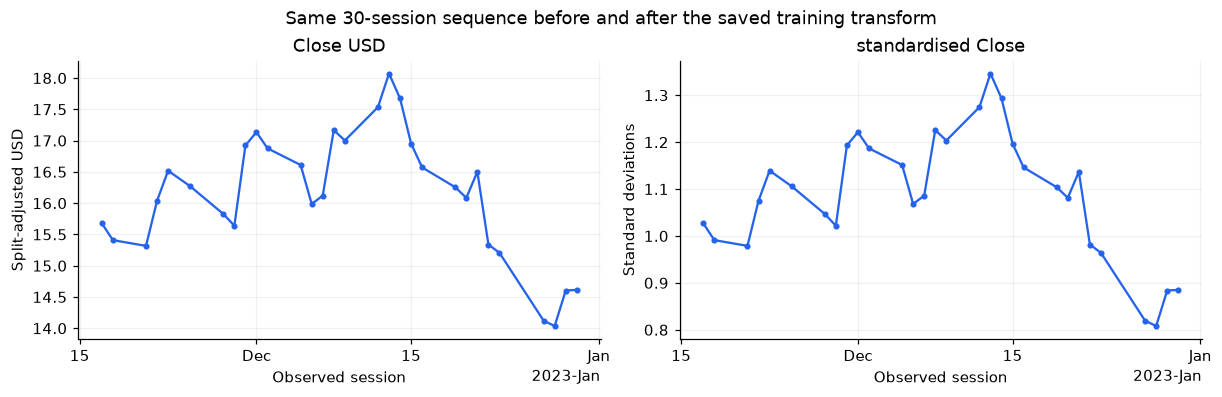

In [5]:
# The saved scalar parameters are the exact inference contract, independently checked above.
input_scaler = Standardisation(**final_runs[0]["scaling"]["input_scaler"])
correction_scaler = Standardisation(**final_runs[0]["scaling"]["correction_scaler"])
eval_mask = ~final.fit_mask
example_index = np.flatnonzero(eval_mask)[0]  # First target, selected without inspecting forecast accuracy.
example_meta = final.dataset.metadata.iloc[example_index]
window = close.loc[example_meta.window_start:example_meta.origin_date]
window_table = pd.DataFrame({"Close USD": window, "standardised Close": input_scaler.transform(window)})
np.testing.assert_array_equal(window.to_numpy(), final.dataset.X[example_index, :, 0])
np.testing.assert_array_equal(window_table["standardised Close"].to_numpy().astype("float32"),
                              final.X[example_index, :, 0])
np.testing.assert_allclose(input_scaler.inverse_transform(window_table["standardised Close"]), window,
                           rtol=0, atol=1e-12)
display(window_table)
unique_fit = close.loc[final.provenance["input_first_date"]:final.provenance["input_last_date"]]
display(pd.DataFrame([{"correct unique-date mean": unique_fit.mean(),
                       "incorrect flattened-window mean": final.dataset.X[final.fit_mask].mean(),
                       "unique dates": len(unique_fit),
                       "repeated window entries": final.dataset.X[final.fit_mask].size}]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, column, unit in zip(axes, window_table.columns, ["Split-adjusted USD", "Standard deviations"]):
    ax.plot(window_table.index, window_table[column], color=BLUE, marker=".")
    ax.set(title=column, ylabel=unit, xlabel="Observed session")
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle("Same 30-session sequence before and after the saved training transform")
plt.show()

The complete development tensor has shape **(2486, 30, 1)**: examples × sessions × features. There are **1,984 fitting** and **502 evaluation** targets. Internal selection uses **1,733 fitting** and **251 evaluation** targets. The last fitting target is excluded from fitting input statistics because it appears only as a label at that boundary; it can legitimately become the first evaluation origin. A validation window may use earlier validation closes once observed, while weights and scalers remain fixed. No target enters its own input.

## 5. Residual dollar-correction forecasting

The learned quantity is a departure from persistence:
\[
\Delta C_{t+1}=C_{t+1}-C_t,\quad
z^{\Delta}_{t+1}=\frac{\Delta C_{t+1}-\mu_\Delta}{s_\Delta},\quad
\widehat C_{t+1}=C_t+s_\Delta\widehat z^\Delta_{t+1}+\mu_\Delta.
\]
The observed origin carries the price level into the final forecast. This reduces the burden of reproducing unfamiliar absolute prices, but input levels and dollar-change distributions can still shift. A linear Dense output permits signed corrections; there is no positivity clamp or claim that this formulation guarantees valid prices in every possible deployment.

**Zero dollars** reproduces persistence. **Zero standardised output** predicts the fitting mean correction, which is generally nonzero. Separate input and target scalers are essential because price levels and one-session changes have different distributions. Inverse-transforming the correction with the price scaler would be incorrect.

In [6]:
training_indices = np.flatnonzero(final.fit_mask)[:4]
training_meta = final.dataset.metadata.iloc[training_indices]
training_origins = final.dataset.X[training_indices, -1, 0]
training_corrections = final.dataset.y[training_indices] - training_origins
training_z = correction_scaler.transform(training_corrections)
np.testing.assert_array_equal(training_z.astype("float32"), final.y[training_indices])
np.testing.assert_allclose(reconstruct_prices(training_origins, training_z, correction_scaler),
                           final.dataset.y[training_indices], rtol=0, atol=1e-12)
display(training_meta[["origin_date", "target_date"]].reset_index(drop=True).assign(
    origin_USD=training_origins, target_USD=final.dataset.y[training_indices],
    correction_USD=training_corrections, standardised_target=training_z))
origin = float(window.iloc[-1])
zero_dollar_z = float(correction_scaler.transform([0.])[0])
zero_cases = np.array([0., zero_dollar_z])
display(pd.DataFrame({"case": ["Zero standardised output", "Zero-dollar correction (persistence)"],
                      "standardised output": zero_cases,
                      "correction USD": correction_scaler.inverse_transform(zero_cases),
                      "forecast USD": reconstruct_prices(np.full(2, origin), zero_cases, correction_scaler)}))
print(f"Final correction mean={correction_scaler.mean:.9f} USD, SD={correction_scaler.scale:.9f} USD.")

,origin_date,target_date,origin_USD,target_USD,correction_USD,standardised_target
0,2015-02-13,2015-02-17,0.557750,0.559500,0.001750,-0.014127
1,2015-02-17,2015-02-18,0.559500,0.553000,-0.006500,-0.035973
2,2015-02-18,2015-02-19,0.553000,0.554500,0.001500,-0.014789
3,2015-02-19,2015-02-20,0.554500,0.558500,0.004000,-0.008169


,case,standardised output,correction USD,forecast USD
0,Zero standardised output,0.000000,0.007085,14.621085
1,Zero-dollar correction (persistence),-0.018761,0.000000,14.614000


Final correction mean=0.007084804 USD, SD=0.377640839 USD.


## 6. Actual selected architecture

The selected configuration is **Input(30,1) → LSTM(16) → Dropout(0.2) → Dense(1)**. We inspect the authoritative constructor and load the actual **seed 42** final checkpoint. Seed 42 is the first prespecified seed, not the best-performing seed. Loading with `compile=False` is sufficient for inference and does not resume optimisation.

For \(u\) units and \(f\) input features, four learned transformations each have input weights, recurrent weights and biases:
\[
N_{\mathrm{LSTM}}=4u(f+u+1)=4(16)(1+16+1)=1152.
\]
The Dense layer adds \(16+1=17\), giving **1,169 trainable parameters**. Weight sharing means this count is not multiplied by 30. Dropout randomly masks activations during training; it has no learned coefficients. Its random-generator state is not a trainable model parameter. The separate Dropout layer acts on the final hidden vector; this is not recurrent dropout inside the LSTM.

In [7]:
display(Code(inspect.getsource(build_model), language="python"))
model42 = tf.keras.models.load_model(BASE / "final/C_seed_42/model.keras", compile=False)
model42.summary()
lstm_layer, dropout_layer, dense_layer = model42.layers
assert model42.input_shape == (None, 30, 1) and model42.output_shape == (None, 1)
assert lstm_layer.units == selected["configuration"]["units"] == 16
assert dropout_layer.rate == selected["configuration"]["dropout"] == .2
assert not lstm_layer.stateful and not lstm_layer.return_sequences
assert lstm_layer.dropout == 0 and lstm_layer.recurrent_dropout == 0
u, f = lstm_layer.units, model42.input_shape[-1]
expected_parameters = 4*u*(f+u+1) + u + 1
assert model42.count_params() == expected_parameters == 1169
assert sum(np.prod(w.shape) for w in model42.trainable_weights) == expected_parameters
assert not dropout_layer.trainable_weights

display(pd.DataFrame([{"layer": layer.__class__.__name__, "input": str(layer.input.shape),
                       "output": str(layer.output.shape), "parameters": layer.count_params()}
                      for layer in model42.layers]))
display(pd.DataFrame([{"weight": w.name, "shape": tuple(w.shape), "values": int(np.prod(w.shape))}
                      for w in model42.trainable_weights]))

def build_model(settings, seed, lookback=30, features=1):
    """Initialise an independent LSTM that predicts a standardised correction."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, features)),
        tf.keras.layers.LSTM(settings["units"], stateful=False),
        tf.keras.layers.Dropout(settings["dropout"], seed=seed),
        tf.keras.layers.Dense(1),
    ])
    # MSE is in correction-standardised units; evaluation reconstructs USD prices.
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=settings["learning_rate"]),
                  loss="mean_squared_error")
    return model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

,layer,input,output,parameters
0,LSTM,"(None, 30, 1)","(None, 16)",1152
1,Dropout,"(None, 16)","(None, 16)",0
2,Dense,"(None, 16)","(None, 1)",17


,weight,shape,values
0,kernel,"(1, 64)",64
1,recurrent_kernel,"(16, 64)",1024
2,bias,"(64,)",64
3,kernel,"(16, 1)",16
4,bias,"(1,)",1


## 7. Training and optimisation

The objective for a minibatch of \(b\) examples is
\[
L=\frac1b\sum_i(\widehat z_i^\Delta-z_i^\Delta)^2.
\]
Backpropagation through time differentiates the 30 shared recurrent steps. Keras `train_on_batch()` computes the forward loss, gradients and Adam updates; the project's `train_model()` controls chronological batches, logging and stopping. This notebook inspects that function but does not invoke it. Adam tracks moving averages of gradients and squared gradients, with bias correction, and scales each parameter's update using those estimates. Learning rate controls the update scale, not the number of examples. [Keras Adam documentation](https://keras.io/api/optimizers/adam/) defines the optimiser contract; exact serialised settings are inspected below.

An epoch is one complete pass over fitting examples. The last internal batch has fewer than 32 examples and is retained. Training loss is a sample-weighted average of batch losses with evolving weights and, for C, active dropout. **Training inference MSE** is recomputed on all fitting examples at the end of each epoch with dropout off; it is directly comparable computationally with internal-validation MSE.

For fixed target scale \(s_\Delta\), USD price error equals USD correction error. Consequently \(\mathrm{RMSE}_{USD}=s_\Delta\sqrt{\mathrm{MSE}_{z}}\), up to float32 representation error. A loss near one is not an error of one dollar. Different stages have different fitted scales, so their standardised losses cannot be compared without considering those scales.

In [8]:
# Read optimiser metadata from the checkpoint; compiling is unnecessary for inference.
import zipfile
with zipfile.ZipFile(BASE / "final/C_seed_42/model.keras") as archive:
    saved_model_config = json.loads(archive.read("config.json"))
optimizer_config = saved_model_config["compile_config"]["optimizer"]["config"]
assert np.isclose(optimizer_config["learning_rate"], selected["configuration"]["learning_rate"])
with pd.option_context("display.float_format", lambda value: f"{value:.8g}"):
    display(pd.Series({k: optimizer_config[k] for k in
                       ["learning_rate", "beta_1", "beta_2", "epsilon", "amsgrad"]}, name="Recorded Adam settings"))
batch_size = selected["configuration"]["batch_size"]
batch_table = pd.DataFrame([{"stage": name, "examples": int(p.fit_mask.sum()),
                             "batch size": batch_size, "updates per epoch": math.ceil(p.fit_mask.sum()/batch_size),
                             "last batch size": int((p.fit_mask.sum()-1)%batch_size+1)}
                            for name, p in [("Internal", internal), ("Final", final)]])
display(batch_table)
assert math.ceil(final.fit_mask.sum()/batch_size) * selected["epochs"] == 1178
# The source shows the actual optimiser call, batch ordering and separate inference losses.
display(Code(inspect.getsource(train_model), language="python"))

learning_rate    0.001
beta_1             0.9
beta_2           0.999
epsilon          1e-07
amsgrad          False
Name: Recorded Adam settings, dtype: object

,stage,examples,batch size,updates per epoch,last batch size
0,Internal,1733,32,55,5
1,Final,1984,32,62,32


def train_model(model, X, y, settings, output, validation=None):
    """Train chronological minibatches and persist history after every epoch."""
    output = Path(output)
    history = []
    tracker = EarlyStopState(settings["patience"]) if validation is not None else None
    batch_size, epochs = settings["batch_size"], settings["epochs"]
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        total_loss = 0.0
        # No shuffling: each epoch traverses the same target-date order.
        for start in range(0, len(X), batch_size):
            stop = min(start + batch_size, len(X))
            model.reset_metrics()
            loss = float(model.train_on_batch(X[start:stop], y[start:stop, None]))
            if not np.isfinite(loss):
                raise ValueError(f"Nonfinite training loss at epoch {epoch}")
            total_loss += loss * (stop - start)
        # Compare both sets using end-of-epoch weights and dropout disabled.
        train_predictions = predict_standardised(model, X)
        row = {"epoch": epoch, "training_loss": total_loss / len(X),
               "training_inference_mse": float(np.mean((train_predictions - y) ** 2)),
               "optimizer_steps": int(model.optimizer.iterations.numpy()),
               "elapsed_seconds": time.perf_counter() - started}
        should_stop = False
        if validation is not None:
            vx, vy = validation
            row["validation_mse"] = float(np.mean((predict_standardised(model, vx) - vy) ** 2))
            should_stop = tracker.observe(model, row["validation_mse"], epoch)
        if not np.isfinite(row["training_inference_mse"]):
            raise ValueError("Nonfinite inference loss")
        history.append(row)
        # Persist progress so a failed run retains its completed epochs.
        (output / "history.json").write_text(json.dumps(history, indent=2, allow_nan=False) + "\n")
        if should_stop:
            break
    terminal_validation_mse = history[-1].get("validation_mse")
    if tracker is not None:
        tracker.restore(model)
    # The restored selection checkpoint is for inference; final fits start afresh.
    model.save(output / "model.keras")
    return {"epochs_completed": len(history), "best_epoch": tracker.best_epoch if tracker else None,
            "best_validation_mse": tracker.best_loss if tracker else None,
            "terminal_validation_mse": terminal_validation_mse,
            "stopped_early": bool(tracker and len(history) < epochs),
            "reached_epoch_cap": len(history) == epochs,
            "elapsed_seconds": time.perf_counter() - started,
            "optimizer_steps": int(model.optimizer.iterations.numpy()),
            "trainable_parameters": model.count_params()}

The internal fit takes **55 updates per epoch** (last batch: 5 examples); the full fit takes **62** (all batches: 32). Each 19-epoch final run therefore records **1,178 optimiser updates**. Samples are chronologically ordered without shuffling; each stateless sample still starts its own recurrent state. This ordering is a recorded training convention. Leakage prevention principally comes from target-date partitions, causal windows and training-only transforms.

## 8. Regularisation and generalisation

Overfitting means fitting idiosyncrasies that do not generalise; underfitting means inadequate fit to relevant structure. Their diagnosis needs evidence, not just a flexible model or a gap between losses from different periods.

For C, dropout uses a Bernoulli mask with keep probability 0.8 and scales retained activations by \(1/0.8\) during training. This preserves each activation's expectation, not its realised value. Inference leaves activations intact. The following calls use the **actual checkpoint's Dropout layer** without gradients or weight updates; the returned masks are an illustration of training-mode behaviour, not a new forecast experiment. [Keras Dropout documentation](https://keras.io/api/layers/regularization_layers/dropout/).

Internal early stopping monitors **2022 inference MSE** after each epoch. Every strict improvement saves a copy of the weights; ten consecutive non-improving epochs stop training. The best weights are restored. Selection checkpoints are inference checkpoints: optimiser moments remain at the stopping epoch and must not be treated as a fully restored training-resume state. Final fits instead start from fresh initialisations and run for a locked number of epochs with no external-validation monitoring.

In [9]:
hidden = lstm_layer(final.X[example_index:example_index+1], training=False)
weights_before = [w.numpy().copy() for w in model42.trainable_weights]
masked_hidden = dropout_layer(hidden, training=True).numpy()[0]
inference_hidden = dropout_layer(hidden, training=False).numpy()[0]
np.testing.assert_array_equal(inference_hidden, hidden.numpy()[0])
for before, after in zip(weights_before, model42.trainable_weights):
    np.testing.assert_array_equal(before, after.numpy())
display(pd.DataFrame({"unit": np.arange(1, u+1), "hidden activation": hidden.numpy()[0],
                      "training-mode dropout": masked_hidden, "inference-mode output": inference_hidden}))
print("No learned weights changed. The realised dropout count need not equal exactly 20% of 16.")
display(Code(inspect.getsource(EarlyStopState), language="python"))

histories = {}
for phase, runs in [("selection", internal_runs), ("final", final_runs)]:
    for run in runs:
        key = (phase, run["configuration_id"], run["seed"])
        folder = BASE / phase / f"{run['configuration_id']}_seed_{run['seed']}"
        assert json.loads((folder / "summary.json").read_text()) == run
        history = pd.DataFrame(json.loads((folder / "history.json").read_text()))
        histories[key] = history
        assert history.epoch.tolist() == list(range(1, run["epochs_completed"]+1))
        updates = math.ceil((internal if phase == "selection" else final).fit_mask.sum()/batch_size)
        np.testing.assert_array_equal(history.optimizer_steps, history.epoch * updates)
        if phase == "selection":
            assert history.loc[history.validation_mse.idxmin(), "epoch"] == run["best_epoch"]
            assert history.validation_mse.min() == run["best_validation_mse"]
            assert run["epochs_completed"] - run["best_epoch"] == search["patience"]
            assert run["stopped_early"] and not run["reached_epoch_cap"]
        else:
            assert "validation_mse" not in history and run["best_epoch"] is None
            assert len(history) == selected["epochs"]

,unit,hidden activation,training-mode dropout,inference-mode output
0,1,-0.054354,-0.067943,-0.054354
1,2,-0.028482,-0.035603,-0.028482
2,3,-0.174730,-0.218412,-0.174730
3,4,-0.130157,0.000000,-0.130157
4,5,0.085756,0.000000,0.085756
5,6,0.009167,0.011459,0.009167
6,7,-0.046764,-0.058455,-0.046764
7,8,0.002504,0.000000,0.002504
8,9,-0.259003,0.000000,-0.259003
9,10,0.144966,0.000000,0.144966


No learned weights changed. The realised dropout count need not equal exactly 20% of 16.


class EarlyStopState:
    """Track strict validation improvements and restore the best model weights."""
    def __init__(self, patience):
        self.patience = patience
        self.best_loss = float("inf")
        self.best_epoch = None
        self.wait = 0
        self.weights = None

    def observe(self, model, loss, epoch):
        """Save an improved checkpoint or count an epoch without improvement."""
        if not np.isfinite(loss):
            raise ValueError("Nonfinite validation loss")
        if loss < self.best_loss:
            self.best_loss, self.best_epoch, self.wait = float(loss), epoch, 0
            self.weights = [w.copy() for w in model.get_weights()]
        else:
            self.wait += 1
        return self.wait >= self.patience

    def restore(self, model):
        """Restore weights selected solely by internal-validation MSE."""
        if self.weights is None:
            raise ValueError("No finite checkpoint available")
        model.set_weights(self.weights)

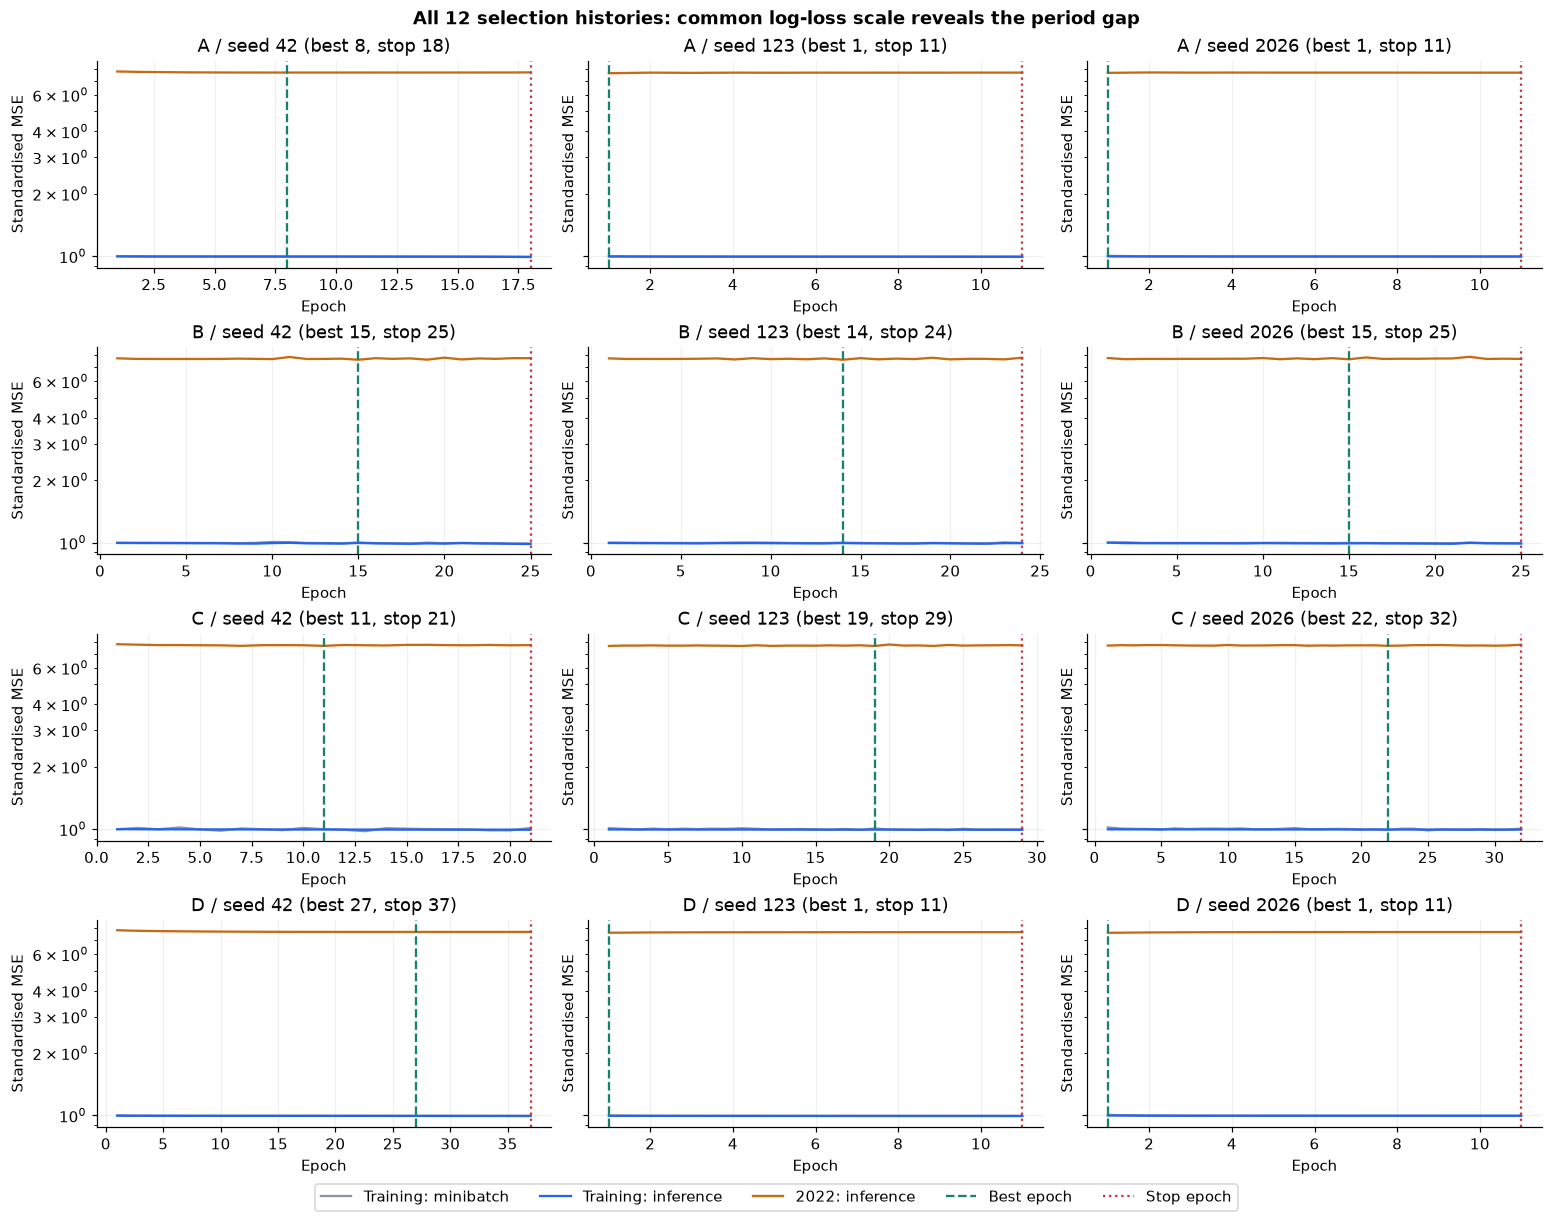

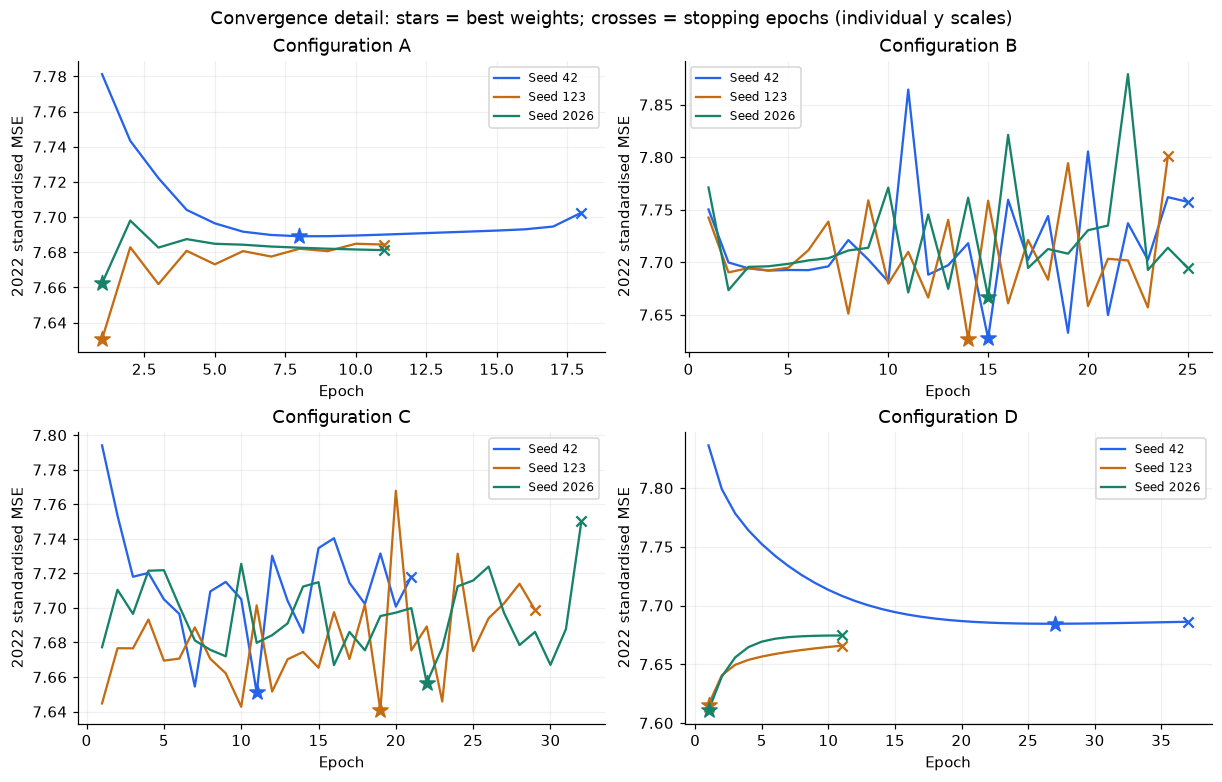

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(14, 11), layout="constrained", sharey=True)
for ax, run in zip(axes.flat, internal_runs):
    h = histories[("selection", run["configuration_id"], run["seed"])]
    ax.plot(h.epoch, h.training_loss, color="#8994a7", label="Training: minibatch")
    ax.plot(h.epoch, h.training_inference_mse, color=BLUE, label="Training: inference")
    ax.plot(h.epoch, h.validation_mse, color=ORANGE, label="2022: inference")
    ax.axvline(run["best_epoch"], color=GREEN, ls="--", label="Best epoch")
    ax.axvline(run["epochs_completed"], color=RED, ls=":", label="Stop epoch")
    ax.set(title=f"{run['configuration_id']} / seed {run['seed']} (best {run['best_epoch']}, stop {run['epochs_completed']})",
           xlabel="Epoch", ylabel="Standardised MSE", yscale="log")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5)
fig.suptitle("All 12 selection histories: common log-loss scale reveals the period gap", weight="bold")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for ax, cfg in zip(axes.flat, search["configurations"]):
    for run in [r for r in internal_runs if r["configuration_id"] == cfg["id"]]:
        h = histories[("selection", cfg["id"], run["seed"])]
        color = SEED_COLORS[run["seed"]]
        ax.plot(h.epoch, h.validation_mse, color=color, label=f"Seed {run['seed']}")
        best = h.loc[h.epoch.eq(run["best_epoch"])].iloc[0]
        ax.scatter(best.epoch, best.validation_mse, color=color, marker="*", s=110, zorder=4)
        ax.scatter(h.epoch.iloc[-1], h.validation_mse.iloc[-1], color=color, marker="x", s=45)
    ax.set(title=f"Configuration {cfg['id']}", xlabel="Epoch", ylabel="2022 standardised MSE")
    ax.legend(fontsize=8)
fig.suptitle("Convergence detail: stars = best weights; crosses = stopping epochs (individual y scales)")
plt.show()

In [11]:
curve_rows = []
for r in internal_runs:
    h = histories[("selection", r["configuration_id"], r["seed"])]
    curve_rows.append({"configuration": r["configuration_id"], "seed": r["seed"],
                       "train MSE first": h.training_inference_mse.iloc[0],
                       "train MSE last": h.training_inference_mse.iloc[-1],
                       "validation MSE first": h.validation_mse.iloc[0],
                       "validation MSE best": h.validation_mse.min(),
                       "validation MSE stop": h.validation_mse.iloc[-1]})
display(pd.DataFrame(curve_rows))
internal_origins = internal.dataset.X[~internal.fit_mask, -1, 0]
internal_truth = internal.dataset.y[~internal.fit_mask]
internal_naive = error_metrics(internal_truth, internal_origins)
zero_dollar_internal = internal.correction_scaler.transform(np.zeros(len(internal_truth)))
naive_internal_mse = np.mean((zero_dollar_internal-internal.y[~internal.fit_mask])**2)
display(pd.DataFrame([{"fitting correction SD USD": internal.correction_scaler.scale,
                       "2022 naive RMSE USD": internal_naive["rmse_usd"],
                       "2022 naive standardised MSE": naive_internal_mse}]))

,configuration,seed,train MSE first,train MSE last,validation MSE first,validation MSE best,validation MSE stop
0,A,42,0.997384,0.990501,7.781248,7.689104,7.702508
1,A,123,0.995983,0.992909,7.630592,7.630592,7.684386
2,A,2026,0.997171,0.995445,7.662320,7.662320,7.681195
3,B,42,0.995810,0.984525,7.750222,7.627529,7.757446
4,B,123,0.995357,0.993025,7.742504,7.626747,7.801075
5,B,2026,0.999762,0.990473,7.771156,7.666784,7.694548
6,C,42,0.997986,0.992023,7.794077,7.651072,7.718076
7,C,123,0.995573,0.992259,7.644736,7.640708,7.698837
8,C,2026,0.996840,0.993454,7.677269,7.656640,7.750183
9,D,42,0.998087,0.994603,7.836305,7.684498,7.686172


,fitting correction SD USD,2022 naive RMSE USD,2022 naive standardised MSE
0,0.278869,0.767339,7.571391


Training inference MSE stays close to one and decreases only slightly. Internal-validation MSE is approximately 7.6–7.8. The fitting correction SD is about **$0.2789**, whereas the 2022 naïve RMSE is **$0.7673**. Even persistence therefore has a large standardised loss in 2022. Period-dependent dollar movements explain why the level of this gap cannot alone diagnose overfitting.

Several runs reduce fitting loss while validation loss deteriorates or fluctuates after a minimum, compatible with mild overfitting or optimisation drift. The histories do not isolate a unique cause or establish clear underfitting. Early stopping demonstrably restores the lowest observed internal MSE; an independent out-of-sample benefit over no stopping was not experimentally isolated. All 12 runs stop before 80 epochs.

## 9. Bounded hyperparameter investigation

The four configurations change one factor relative to A. Batch size stays 32 and lookback stays 30. Seeds **42, 123 and 2026** are paired across configurations to report variation rather than select a favourable initialisation. Different dimensions and dropout paths mean pairing does not imply identical random trajectories. Three seeds are a small stability check, not a significance test.

| Configuration | LSTM units | Post-LSTM dropout | Adam learning rate | Contrast with A |
|---|---:|---:|---:|---|
| A | 16 | 0 | 0.001 | Reference |
| B | 32 | 0 | 0.001 | Capacity |
| C | 16 | 0.2 | 0.001 | Regularisation |
| D | 16 | 0 | 0.0003 | Learning rate |

The **2022 internal** period chooses checkpoints and configuration. The **2023–2024 external validation** period compares the locked configuration with baselines. It does not select epochs or seeds. MAE selects configurations, while MSE selects each run's checkpoint; these related criteria need not rank every epoch identically. This is the predefined protocol, not a claim that each checkpoint minimises MAE.

,units,dropout,batch_size,learning_rate
id,,,,
A,16,0.000000,32,0.001000
B,32,0.000000,32,0.001000
C,16,0.200000,32,0.001000
D,16,0.000000,32,0.000300


,configuration,seed,MAE USD,RMSE USD,best epoch,stop epoch,updates,parameters,status
0,A,42,0.605276,0.773281,8,18,990,1169,complete
1,A,123,0.603904,0.770333,1,11,605,1169,complete
2,A,2026,0.604458,0.771933,1,11,605,1169,complete
3,B,42,0.604207,0.770179,15,25,1375,4385,complete
4,B,123,0.604134,0.770139,14,24,1320,4385,complete
5,B,2026,0.605396,0.772158,15,25,1375,4385,complete
6,C,42,0.604423,0.771366,11,21,1155,1169,complete
7,C,123,0.604396,0.770844,19,29,1595,1169,complete
8,C,2026,0.604582,0.771647,22,32,1760,1169,complete
9,D,42,0.605192,0.773050,27,37,2035,1169,complete


configuration,A minus A (USD),B minus A (USD),C minus A (USD),D minus A (USD)
seed,,,,
42,0.000000,-0.001069,-0.000854,-0.000085
123,0.000000,0.000230,0.000492,-0.000414
2026,0.000000,0.000938,0.000124,-0.001111


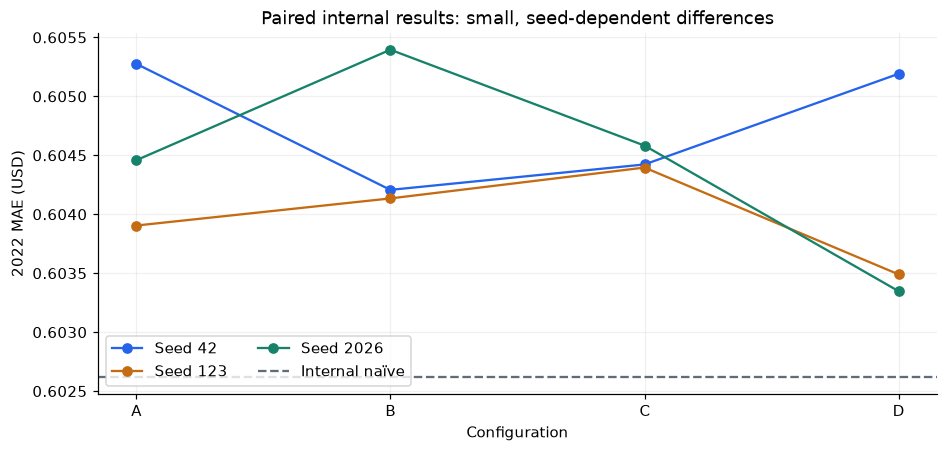

In [12]:
configuration_table = pd.DataFrame(search["configurations"]).set_index("id")
display(configuration_table)
run_table = pd.DataFrame([{"configuration": r["configuration_id"], "seed": r["seed"],
                           "MAE USD": r["evaluation_metrics"]["mae_usd"],
                           "RMSE USD": r["evaluation_metrics"]["rmse_usd"],
                           "best epoch": r["best_epoch"], "stop epoch": r["epochs_completed"],
                           "updates": r["optimizer_steps"], "parameters": r["trainable_parameters"],
                           "status": r["status"]} for r in internal_runs])
display(run_table)
paired = run_table.pivot(index="seed", columns="configuration", values="MAE USD")
display(paired.subtract(paired["A"], axis=0).rename(columns=lambda c: f"{c} minus A (USD)"))
fig, ax = plt.subplots(figsize=(8.5, 4), layout="constrained")
for seed in SEEDS:
    ax.plot(paired.columns, paired.loc[seed], marker="o", color=SEED_COLORS[seed], label=f"Seed {seed}")
ax.axhline(internal_naive["mae_usd"], color="#5f6d7a", ls="--", label="Internal naïve")
ax.set(xlabel="Configuration", ylabel="2022 MAE (USD)", title="Paired internal results: small, seed-dependent differences")
ax.legend(ncol=2)
plt.show()

Increasing capacity to 32 units does not improve mean internal MAE in this search. C has the smallest MAE spread, but its dropout benefit is not established generally. D has the lowest mean MAE, yet seed 42's best epoch shifts from 8 to 27 while its other seeds peak at epoch 1; reducing learning rate does not uniformly improve convergence or stability. Every configuration's mean remains above internal persistence. No additional configuration or replacement run is justified by an unfavourable result.

## 10. Configuration selection and final training

The predefined rule uses the complete three-seed results:

1. Retain configurations with mean MAE within **1% of the lowest mean**.
2. Prefer fewer LSTM units.
3. Prefer lower sample SD of MAE, then lower mean MAE, then configuration ID.

The tolerance is a practical selection rule, **not a statistical equivalence interval**. Re-executing `choose_configuration()` below reproduces the recorded selection. D has the lowest mean, but all four enter the tolerance band. B loses on capacity; C has the smallest spread among the 16-unit alternatives.

For C, best epochs **11, 19 and 22** give median **19**. Three fresh models then fit all 2015–2022 eligible targets for 19 epochs. Scalers are fitted again on that expanded training interval. These are independent fixed-epoch fits, not extensions of the internal checkpoints; they do not monitor 2023–2024 loss.

,configuration_id,eligible,units,mean_mae,std_mae,mean_rmse,std_rmse,within 1% band
0,A,True,16,0.604546,0.000690,0.771849,0.001476,True
1,B,True,32,0.604579,0.000708,0.770825,0.001154,True
2,C,True,16,0.604467,0.000101,0.771286,0.000408,True
3,D,True,16,0.604010,0.001026,0.770654,0.002079,True


Tolerance upper bound: 0.610049681 USD
Selected C; best epochs [11, 19, 22]; median = 19.


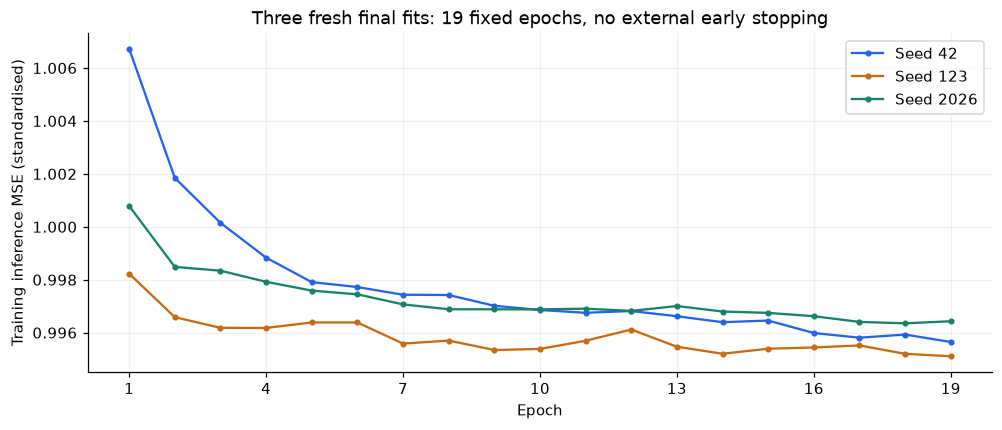

In [13]:
replayed_selection = choose_configuration(internal_runs, search["configurations"], SEEDS)
for key, value in replayed_selection.items(): assert value == selected[key]
assert selected == json.loads((BASE / "selection/selection.json").read_text()) == results["selection"]
selection_table = pd.DataFrame(replayed_selection["groups"])
selection_table["within 1% band"] = selection_table.mean_mae <= replayed_selection["mae_band_upper"]
display(selection_table)
best_c = [r["best_epoch"] for r in internal_runs if r["configuration_id"] == selected["selected_id"]]
print(f"Tolerance upper bound: {replayed_selection['mae_band_upper']:.9f} USD")
print(f"Selected {selected['selected_id']}; best epochs {best_c}; median = {selected['epochs']}.")
assert all(r["settings"] == dict(selected["configuration"], epochs=selected["epochs"]) for r in final_runs)
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
for run in final_runs:
    h = histories[("final", run["configuration_id"], run["seed"])]
    ax.plot(h.epoch, h.training_inference_mse, marker=".", color=SEED_COLORS[run["seed"]], label=f"Seed {run['seed']}")
ax.set(xlabel="Epoch", ylabel="Training inference MSE (standardised)",
       title="Three fresh final fits: 19 fixed epochs, no external early stopping")
ax.set_xticks([1, 4, 7, 10, 13, 16, 19]); ax.legend()
plt.show()

### Checkpoint and experiment reproduction

We now load **all 15 checkpoints**, use the actual inference and reconstruction functions, and compare with each run's saved dates, predictions, metrics and scaling provenance. For selection models we additionally reproduce the restored best-epoch MSE. This verifies inference from saved weights; it does not claim an independently repeated training experiment.

JSON predictions were written to ten decimal places. A maximum **$0.000001** prediction discrepancy is allowed for serialisation/float32 inference, and metric tolerance is **$0.0000001**. The observed differences are displayed, not hidden. The original CPU environment, paired seeds and deterministic operations are recorded, but bitwise training reproducibility across environments is not established. [TensorFlow determinism requirements](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).

In [14]:
def read_forecasts(path):
    """Read saved development forecasts and check their temporal bounds."""
    table = pd.read_json(path)
    for column in ["origin_date", "target_date"]:
        table[column] = pd.to_datetime(table[column])
    assert table.target_date.is_unique and table.target_date.is_monotonic_increasing
    assert table.target_date.max() <= pd.Timestamp(config["validation_end"])
    assert (table.origin_date < table.target_date).all()
    return table

verification_rows, final_predictions, final_models = [], {}, {42: model42}
for phase, runs, prepared in [("selection", internal_runs, internal), ("final", final_runs, final)]:
    mask = ~prepared.fit_mask
    expected_meta = prepared.dataset.metadata.loc[mask].reset_index(drop=True)
    true_prices = prepared.dataset.y[mask]
    origins = prepared.dataset.X[mask, -1, 0]
    for run in runs:
        folder = BASE / phase / f"{run['configuration_id']}_seed_{run['seed']}"
        saved = read_forecasts(folder / "predictions.json")
        for column in ["target_date", "origin_date"]:
            assert saved[column].tolist() == expected_meta[column].tolist()
        np.testing.assert_allclose(saved.actual_close, true_prices, rtol=0, atol=1e-9)
        np.testing.assert_allclose(saved.origin_close, origins, rtol=0, atol=1e-9)
        checkpoint = (model42 if phase == "final" and run["seed"] == 42 else
                      tf.keras.models.load_model(folder / "model.keras", compile=False))
        assert checkpoint.count_params() == run["trainable_parameters"]
        z_prediction = predict_standardised(checkpoint, prepared.X[mask])
        usd_prediction = reconstruct_prices(origins, z_prediction, prepared.correction_scaler)
        np.testing.assert_allclose(usd_prediction, saved.prediction, rtol=0, atol=1e-6)
        np.testing.assert_allclose(prepared.correction_scaler.inverse_transform(z_prediction),
                                   saved.predicted_correction, rtol=0, atol=1e-6)
        metrics = error_metrics(true_prices, usd_prediction)
        for key in ["mae_usd", "rmse_usd"]:
            np.testing.assert_allclose(metrics[key], run["evaluation_metrics"][key], rtol=0, atol=1e-7)
        if phase == "selection":
            mse = float(np.mean((z_prediction-prepared.y[mask])**2))
            np.testing.assert_allclose(mse, run["best_validation_mse"], rtol=1e-6, atol=1e-8)
        else:
            final_predictions[run["seed"]] = usd_prediction
            final_models[run["seed"]] = checkpoint
        verification_rows.append({"phase": phase, "configuration": run["configuration_id"], "seed": run["seed"],
                                  "dates": len(saved), "max prediction discrepancy USD": float(np.max(np.abs(usd_prediction-saved.prediction))),
                                  "MAE USD": metrics["mae_usd"], "RMSE USD": metrics["rmse_usd"]})
verification_table = pd.DataFrame(verification_rows)
display(verification_table)
print(f"All {len(verification_table)} saved checkpoints reproduced without training.")

,phase,configuration,seed,dates,max prediction discrepancy USD,MAE USD,RMSE USD
0,selection,A,42,251,0.000000,0.605276,0.773281
1,selection,A,123,251,0.000000,0.603904,0.770333
2,selection,A,2026,251,0.000000,0.604458,0.771933
3,selection,B,42,251,0.000000,0.604207,0.770179
4,selection,B,123,251,0.000000,0.604134,0.770139
5,selection,B,2026,251,0.000000,0.605396,0.772158
6,selection,C,42,251,0.000000,0.604423,0.771366
7,selection,C,123,251,0.000000,0.604396,0.770844
8,selection,C,2026,251,0.000000,0.604582,0.771647
9,selection,D,42,251,0.000000,0.605192,0.773050


All 15 saved checkpoints reproduced without training.


## 11. Complete NVIDIA forecasting demonstration

Use **seed 42** and the **first validation target, 3 January 2023**, chosen by date rather than forecast quality. The 30-session input ends on **30 December 2022**. Only that history is supplied to the model. The target's actual Close is retrieved afterward for scoring; it never enters prediction or reconstruction.

The model emits one standardised correction. `inverse_transform()` restores dollars, and `reconstruct_prices()` adds the known origin. These are the same functions used by the experiment runner. The standardised input tensor has shape **(1,30,1)**: one example, thirty sessions, one feature.

,Close USD,standardised Close
Historical session,,
2022-11-17,15.677000,1.026886
2022-11-18,15.409000,0.991154
2022-11-21,15.317000,0.978887
2022-11-22,16.038000,1.075019
2022-11-23,16.518999,1.139152
2022-11-25,16.270000,1.105952
2022-11-28,15.827000,1.046886
2022-11-29,15.639000,1.021820
2022-11-30,16.923000,1.193018


forecast origin                           2022-12-30
target session                            2023-01-03
model input shape                         (1, 30, 1)
origin Close USD / naive                   14.614000
standardised predicted correction           0.052257
predicted correction USD                    0.026819
LSTM prediction USD                        14.640820
actual Close USD                           14.315000
signed error (prediction - actual) USD      0.325820
absolute error USD                          0.325820
Name: Actual checkpoint inference, dtype: object

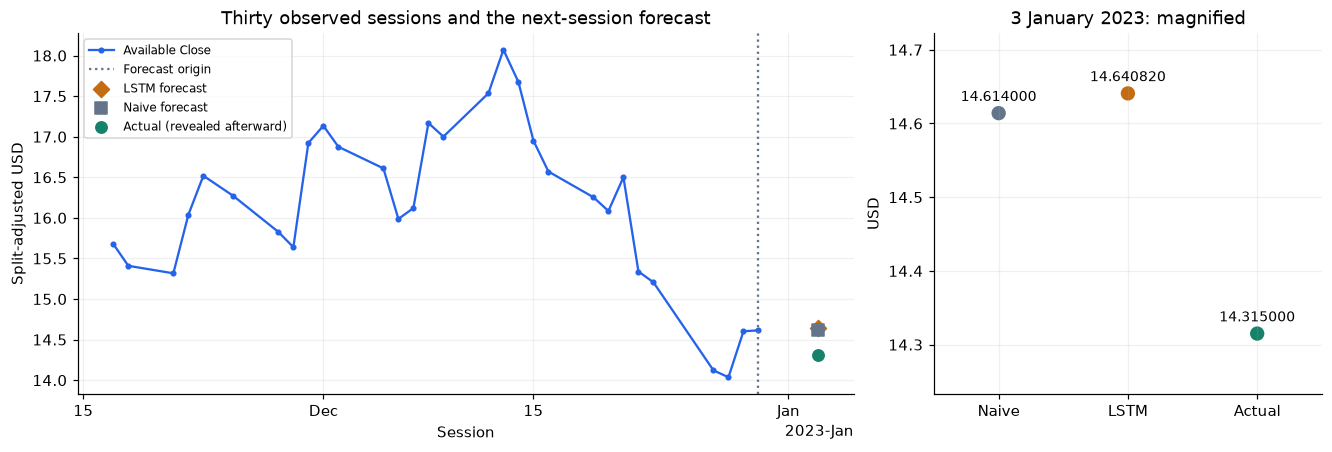

In [15]:
display(window_table.rename_axis("Historical session"))
X_example = input_scaler.transform(window.to_numpy()[None, :, None]).astype("float32")
np.testing.assert_array_equal(X_example, final.X[example_index:example_index+1])
z_prediction = predict_standardised(model42, X_example)
dollar_prediction = correction_scaler.inverse_transform(z_prediction)
price_prediction = reconstruct_prices(np.array([origin]), z_prediction, correction_scaler)
# Reveal the next-session observation only after issuing the forecast.
actual = float(final.dataset.y[example_index])
forecast_error = float(price_prediction[0] - actual)
np.testing.assert_allclose(price_prediction[0], final_predictions[42][0], rtol=0, atol=1e-7)
np.testing.assert_allclose(error_metrics([actual], price_prediction)["mae_usd"], abs(forecast_error))
demo = pd.Series({"forecast origin": str(example_meta.origin_date.date()),
                  "target session": str(example_meta.target_date.date()), "model input shape": str(X_example.shape),
                  "origin Close USD / naive": origin, "standardised predicted correction": z_prediction[0],
                  "predicted correction USD": dollar_prediction[0], "LSTM prediction USD": price_prediction[0],
                  "actual Close USD": actual, "signed error (prediction - actual) USD": forecast_error,
                  "absolute error USD": abs(forecast_error)}, name="Actual checkpoint inference")
display(demo)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(window.index, window, marker=".", color=BLUE, label="Available Close")
axes[0].axvline(example_meta.origin_date, color="#64748b", ls=":", label="Forecast origin")
for value, label, color, marker in [(price_prediction[0], "LSTM forecast", ORANGE, "D"),
                                    (origin, "Naive forecast", "#64748b", "s"),
                                    (actual, "Actual (revealed afterward)", GREEN, "o")]:
    axes[0].scatter(example_meta.target_date, value, color=color, marker=marker, s=55, label=label, zorder=4)
axes[0].set(title="Thirty observed sessions and the next-session forecast", ylabel="Split-adjusted USD", xlabel="Session")
locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
axes[0].xaxis.set_major_locator(locator); axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[0].legend(fontsize=8)
axes[1].scatter([0, 1, 2], [origin, price_prediction[0], actual], color=["#64748b", ORANGE, GREEN], s=70)
axes[1].set(xticks=[0, 1, 2], xticklabels=["Naive", "LSTM", "Actual"], ylabel="USD", title="3 January 2023: magnified")
for pos, value in enumerate([origin, price_prediction[0], actual]):
    axes[1].annotate(f"{value:.6f}", (pos, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
axes[1].margins(x=.25, y=.25)
plt.show()

The checkpoint predicts a small positive correction for this session, while the realised close falls below the origin. This example demonstrates the computational path; it does not establish average forecasting skill. During rolling evaluation, the observed close for 3 January becomes available in the next window. Weights and both scalers remain unchanged; no target is used in its own forecast and no evaluation-time fitting occurs.

## 12. Forecasting performance and error analysis

All comparisons use the same **502 targets**, from 3 January 2023 to 31 December 2024. We recalculate each run's metrics from loaded checkpoints, verify both baselines' saved dates and actual prices, and use the project's `error_metrics()`:
\[
\operatorname{MAE}=n^{-1}\sum_i|\widehat C_i-C_i|,\qquad
\operatorname{RMSE}=\sqrt{n^{-1}\sum_i(\widehat C_i-C_i)^2}.
\]
Both have USD units; RMSE gives more influence to large errors. The LSTM aggregate below is the **mean of three run metrics**, with sample SD (ddof=1). It is not an averaged-prediction ensemble or a confidence interval. Relative MAE change is \(100(\mathrm{MAE}_{LSTM}/\mathrm{MAE}_{naive}-1)\); positive means worse.

In [16]:
truth = final.dataset.y[eval_mask]
dates = final.dataset.metadata.loc[eval_mask, "target_date"].reset_index(drop=True)
origins = final.dataset.X[eval_mask, -1, 0]
naive = naive_predictions(final.dataset)[eval_mask]
naive_saved = read_forecasts(ROOT / "artifacts/naive_v1/validation_predictions.json")
arima_saved = read_forecasts(ROOT / "artifacts/arima_v1/validation_predictions.json")
for saved in [naive_saved, arima_saved]:
    assert saved.target_date.tolist() == dates.tolist()
    assert saved.origin_date.tolist() == final.dataset.metadata.loc[eval_mask, "origin_date"].tolist()
    np.testing.assert_allclose(saved.actual_close, truth, rtol=0, atol=1e-9)
np.testing.assert_allclose(naive_saved.prediction, naive, rtol=0, atol=1e-9)
forecasts = {"Naive": naive, "ARIMA": arima_saved.arima_prediction.to_numpy(),
             **{f"LSTM seed {seed}": final_predictions[seed] for seed in SEEDS}}
metrics_table = pd.DataFrame([{"model": name, **error_metrics(truth, prediction)}
                              for name, prediction in forecasts.items()]).set_index("model")
for name in ["naive", "arima"]:
    label = "Naive" if name == "naive" else "ARIMA"
    for key in ["mae_usd", "rmse_usd"]:
        np.testing.assert_allclose(metrics_table.loc[label, key], results["baselines"][name][key], rtol=0, atol=1e-7)
lstm_metrics = metrics_table.loc[[f"LSTM seed {seed}" for seed in SEEDS], ["mae_usd", "rmse_usd"]]
aggregate = pd.DataFrame({"mean": lstm_metrics.mean(), "sample SD": lstm_metrics.std(ddof=1)})
for metric in aggregate.index:
    np.testing.assert_allclose(aggregate.loc[metric], [results["external_aggregate"][metric]["mean"],
                                                       results["external_aggregate"][metric]["std"]], rtol=0, atol=1e-7)
display(metrics_table); display(aggregate)
relative_mae = 100*(aggregate.loc["mae_usd", "mean"]/metrics_table.loc["Naive", "mae_usd"]-1)
print(f"LSTM three-seed mean MAE is {relative_mae:.4f}% higher than naive.")
assert (lstm_metrics > metrics_table.loc["Naive", ["mae_usd", "rmse_usd"]]).all().all()

,n,mae_usd,rmse_usd
model,,,
Naive,502,1.689494,2.589324
ARIMA,502,1.720201,2.612846
LSTM seed 42,502,1.697893,2.591403
LSTM seed 123,502,1.720407,2.616065
LSTM seed 2026,502,1.696768,2.594212


,mean,sample SD
mae_usd,1.705023,0.013335
rmse_usd,2.600560,0.013501


LSTM three-seed mean MAE is 0.9191% higher than naive.


,year,model,n,mae_usd,rmse_usd
0,2023,Naive,250,0.730728,1.022887
1,2023,ARIMA,250,0.736197,1.022374
2,2023,LSTM seed 42,250,0.745984,1.039643
3,2023,LSTM seed 123,250,0.752150,1.045670
4,2023,LSTM seed 2026,250,0.739541,1.032369
5,2024,Naive,252,2.640651,3.509699
6,2024,ARIMA,252,2.696395,3.544404
7,2024,LSTM seed 42,252,2.642248,3.507872
8,2024,LSTM seed 123,252,2.680980,3.542390
9,2024,LSTM seed 2026,252,2.646398,3.514133


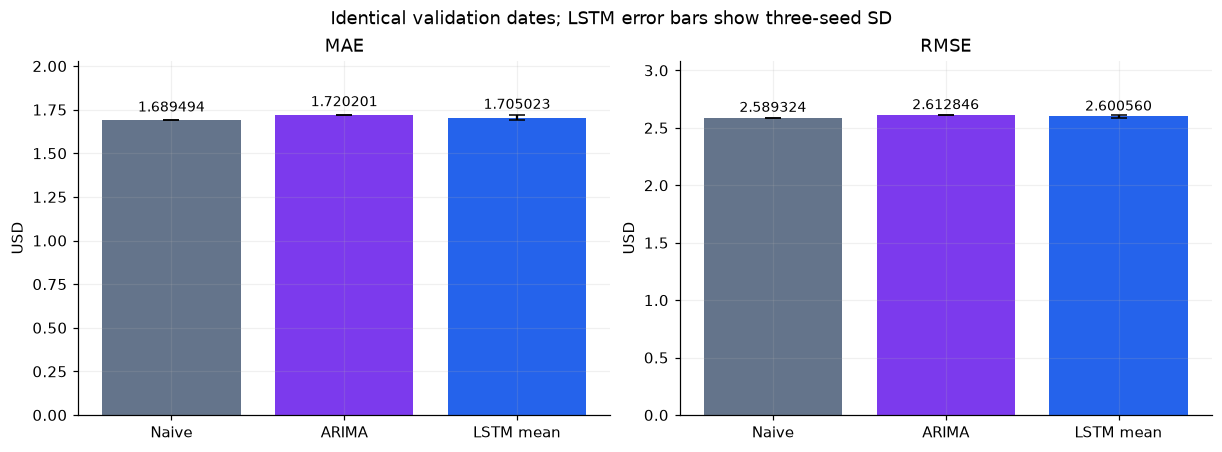

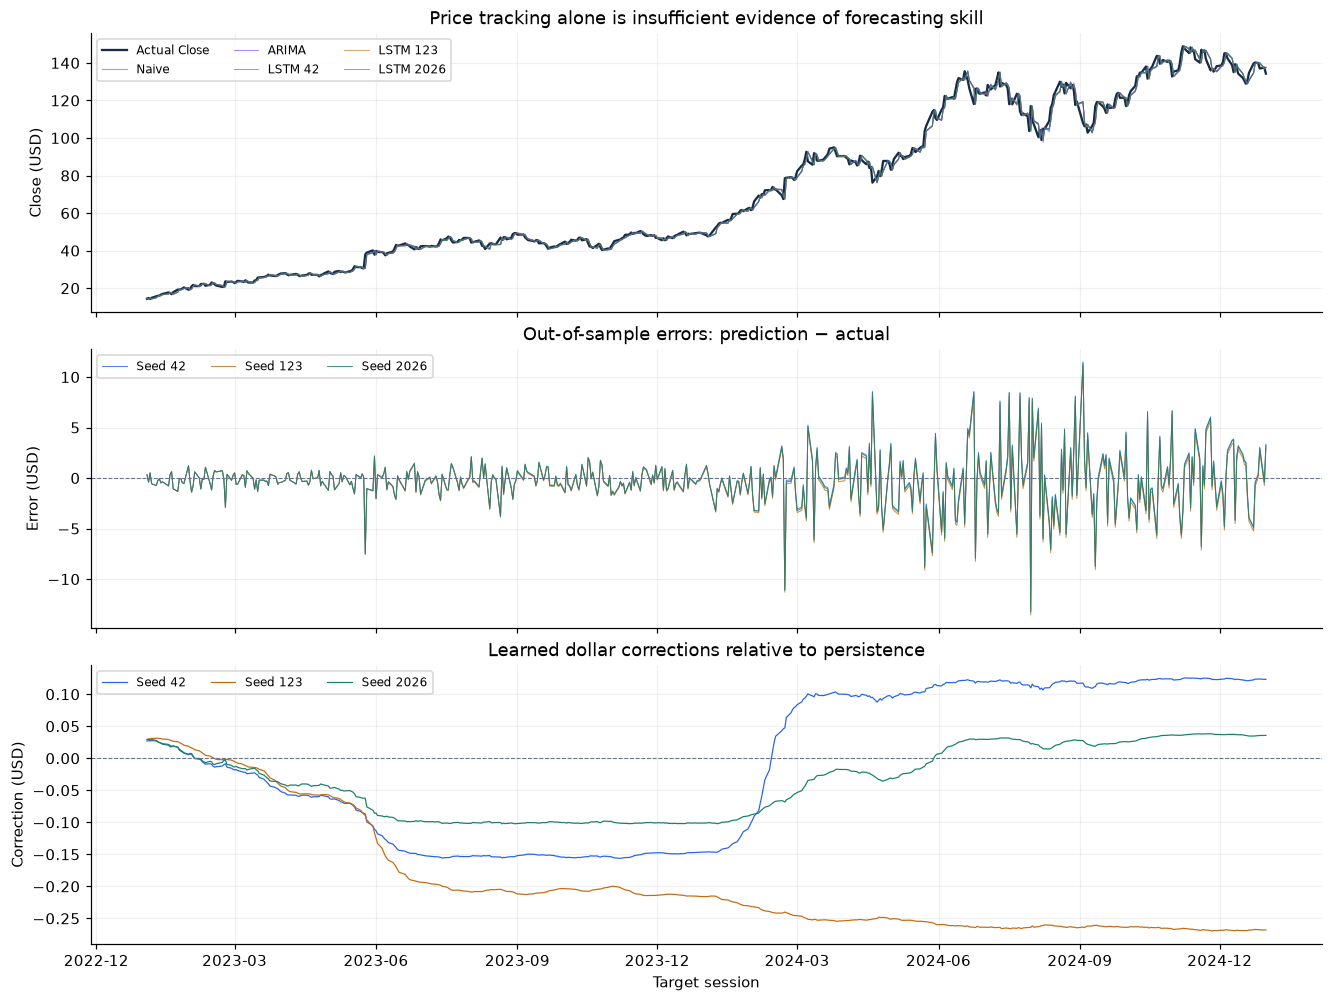

In [17]:
annual_rows = []
for year in sorted(dates.dt.year.unique()):
    mask = dates.dt.year.eq(year).to_numpy()
    for name, prediction in forecasts.items():
        annual_rows.append({"year": year, "model": name, **error_metrics(truth[mask], prediction[mask])})
annual = pd.DataFrame(annual_rows)
display(annual)
for r in final_runs:
    for year, recorded in r["by_year"].items():
        computed = annual.loc[(annual.year == int(year)) & (annual.model == f"LSTM seed {r['seed']}")].iloc[0]
        for key in ["mae_usd", "rmse_usd"]: np.testing.assert_allclose(computed[key], recorded[key], rtol=0, atol=1e-7)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric, title in zip(axes, ["mae_usd", "rmse_usd"], ["MAE", "RMSE"]):
    values = [metrics_table.loc["Naive", metric], metrics_table.loc["ARIMA", metric], aggregate.loc[metric, "mean"]]
    ax.bar(["Naive", "ARIMA", "LSTM mean"], values, color=[MODEL_COLORS["Naive"], ARIMA_COLOR, BLUE],
           yerr=[0, 0, aggregate.loc[metric, "sample SD"]], capsize=5)
    for i, v in enumerate(values): ax.text(i, v+.05, f"{v:.6f}", ha="center", fontsize=9)
    ax.set(title=title, ylabel="USD", ylim=(0, max(values)*1.18))
fig.suptitle("Identical validation dates; LSTM error bars show three-seed SD")
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), layout="constrained", sharex=True)
axes[0].plot(dates, truth, color="#172b45", lw=1.5, label="Actual Close")
axes[0].plot(dates, naive, color=MODEL_COLORS["Naive"], lw=.8, alpha=.6, label="Naive")
axes[0].plot(dates, forecasts["ARIMA"], color=ARIMA_COLOR, lw=.7, alpha=.6, label="ARIMA")
for seed in SEEDS:
    axes[0].plot(dates, final_predictions[seed], color=SEED_COLORS[seed], lw=.65, alpha=.6, label=f"LSTM {seed}")
    axes[1].plot(dates, final_predictions[seed]-truth, color=SEED_COLORS[seed], lw=.65, alpha=.8, label=f"Seed {seed}")
    axes[2].plot(dates, final_predictions[seed]-naive, color=SEED_COLORS[seed], lw=.8, label=f"Seed {seed}")
axes[0].set(title="Price tracking alone is insufficient evidence of forecasting skill", ylabel="Close (USD)")
axes[1].set(title="Out-of-sample errors: prediction − actual", ylabel="Error (USD)")
axes[2].set(title="Learned dollar corrections relative to persistence", ylabel="Correction (USD)", xlabel="Target session")
for ax in axes:
    ax.legend(ncol=3, fontsize=8)
for ax in axes[1:]: ax.axhline(0, color="#64748b", ls="--", lw=.7)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3)); axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.show()

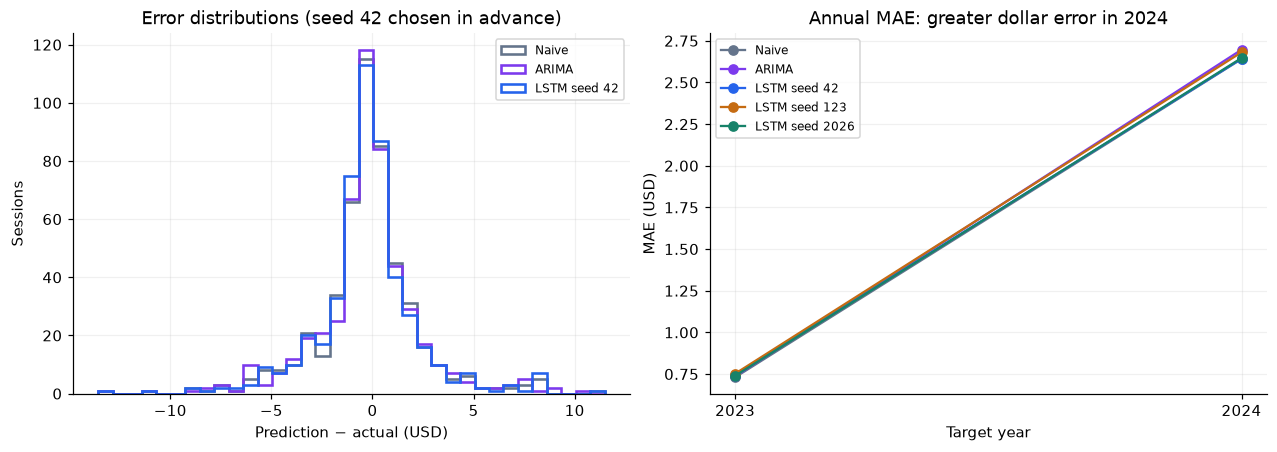

,target,actual dollar movement,predicted correction seed42,signed error seed42,absolute error seed42
0,2024-07-31,13.289993,0.109891,-13.180103,13.180103
1,2024-09-03,-11.370003,0.117437,11.487440,11.487440
2,2024-02-22,11.066002,0.047602,-11.018400,11.018400
3,2024-05-23,8.849007,0.103588,-8.745419,8.745419
4,2024-09-11,8.810005,0.111927,-8.698078,8.698078


,model,five largest errors / total squared error (%),mean signed error USD,maximum absolute error USD
0,Naive,17.359746,-0.238398,13.289993
1,ARIMA,16.107610,-0.241925,12.914378
2,LSTM seed 42,17.181861,-0.246636,13.180103
3,LSTM seed 123,17.466038,-0.431143,13.554039
4,LSTM seed 2026,17.337324,-0.273737,13.267827


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), layout="constrained")
all_errors = np.concatenate([prediction-truth for prediction in forecasts.values()])
bins = np.linspace(all_errors.min(), all_errors.max(), 36)
for name, color in [("Naive", "#64748b"), ("ARIMA", ARIMA_COLOR), ("LSTM seed 42", BLUE)]:
    axes[0].hist(forecasts[name]-truth, bins=bins, histtype="step", lw=1.7, color=color, label=name)
axes[0].set(title="Error distributions (seed 42 chosen in advance)", xlabel="Prediction − actual (USD)", ylabel="Sessions")
axes[0].legend(fontsize=8)
for i, name in enumerate(forecasts):
    rows = annual.loc[annual.model.eq(name)]
    axes[1].plot(rows.year, rows.mae_usd, marker="o", color=MODEL_COLORS[name], label=name)
axes[1].set(title="Annual MAE: greater dollar error in 2024", xlabel="Target year", ylabel="MAE (USD)", xticks=[2023, 2024])
axes[1].legend(fontsize=8)
plt.show()

error42 = final_predictions[42]-truth
extreme_positions = np.argsort(np.abs(error42))[-5:][::-1]
display(pd.DataFrame({"target": dates.iloc[extreme_positions].to_numpy(),
                      "actual dollar movement": (truth-naive)[extreme_positions],
                      "predicted correction seed42": (final_predictions[42]-naive)[extreme_positions],
                      "signed error seed42": error42[extreme_positions],
                      "absolute error seed42": np.abs(error42[extreme_positions])}))
tail_rows = []
for name, prediction in forecasts.items():
    sq_error = (prediction-truth)**2
    tail_rows.append({"model": name, "five largest errors / total squared error (%)":
                      100*np.sort(sq_error)[-5:].sum()/sq_error.sum(),
                      "mean signed error USD": float((prediction-truth).mean()),
                      "maximum absolute error USD": float(np.abs(prediction-truth).max())})
display(pd.DataFrame(tail_rows))

The three-seed mean is **MAE $1.705023 ± $0.013335** and **RMSE $2.600560 ± $0.013501** (sample SD). Naïve gives **$1.689494 / $2.589324**; ARIMA gives **$1.720201 / $2.612846**. Every LSTM seed has higher MAE and RMSE than naïve. Mean LSTM MAE is about **0.92% higher**. Mean LSTM errors are lower than ARIMA, but seed 123 is worse than ARIMA on both metrics; no statistical superiority is established.

Price curves almost overlap because the origin already carries most of the price level. The error and correction panels reveal what that visual similarity conceals. The largest misses coincide with large realised dollar changes, while learned corrections are small by comparison. This describes a numerical relationship, not a causal attribution to news or a proof that those moves were unpredictable. Annual tables show much larger dollar errors in 2024. The top-five contribution to squared error illustrates why RMSE exceeds MAE; no extreme observations are removed.

## 13. Critical methodological assessment

The integrity checks support the implemented protocol. They do not establish that the representation is optimal. We quantify distribution changes using only fitting and development observations. Annual return calculations retain the previous session at each boundary; percentage returns are descriptive diagnostics, not a new modelling target.

Absolute input levels can move far outside their fitting range even after training-only standardisation. Correct standardisation must not use later statistics to make that shift disappear. The persistence connection handles the known price level in the output, but dollar-correction variance may still increase with price. Larger standardised inputs may alter gate behaviour; the following distribution evidence does **not** prove gate saturation or identify the cause of forecast errors.

,period,sessions,Close minimum USD,Close maximum USD,dollar-change SD USD (ddof=1),return SD percentage points (ddof=1)
0,Fitting 2015–2021,1763,0.478500,33.375999,0.276653,2.865662
1,Internal 2022,251,11.227000,30.121000,0.766600,3.982006
2,External 2023,250,14.265000,50.409000,1.015345,3.050845
3,External 2024,252,47.569000,148.880005,3.500495,3.307395


maximum fitting input USD                            33.375999
maximum validation Close USD                        148.880005
validation closes above fitting maximum             403.000000
validation forecast origins above fitting maximum   402.000000
maximum validation Close z-score                     18.787090
dtype: float64

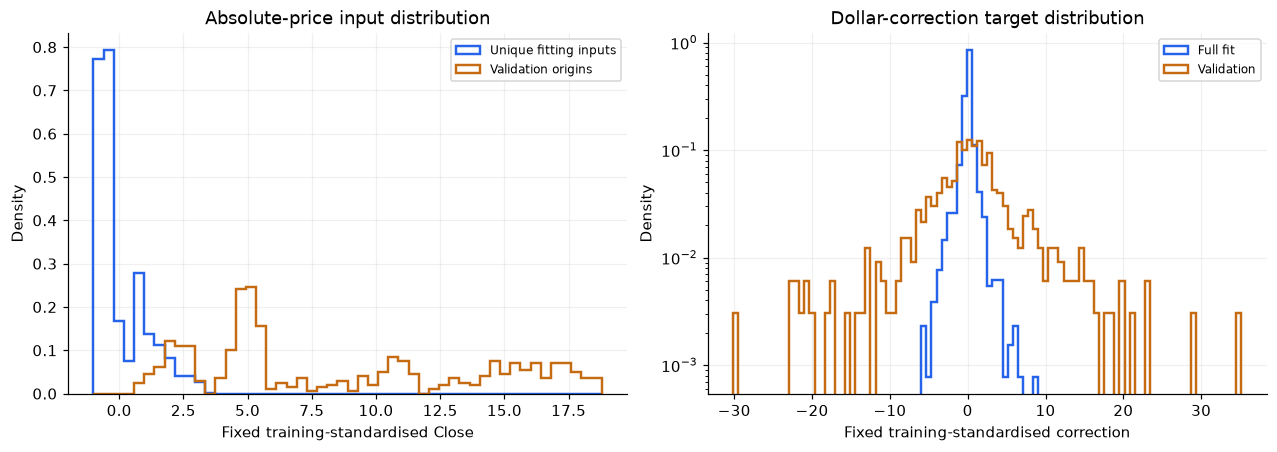

In [19]:
changes = close.diff()
percentage_returns = close.pct_change(fill_method=None) * 100
periods = {"Fitting 2015–2021": (config["start"], search["internal_fit_end"]),
           "Internal 2022": ("2022-01-01", config["train_end"]),
           "External 2023": ("2023-01-01", "2023-12-31"),
           "External 2024": ("2024-01-01", config["validation_end"])}
distribution_rows = []
for name, (start, end) in periods.items():
    prices = close.loc[start:end]
    distribution_rows.append({"period": name, "sessions": len(prices), "Close minimum USD": prices.min(),
                               "Close maximum USD": prices.max(), "dollar-change SD USD (ddof=1)": changes.loc[start:end].std(),
                               "return SD percentage points (ddof=1)": percentage_returns.loc[start:end].std()})
display(pd.DataFrame(distribution_rows))
validation_prices = close.loc["2023-01-01":config["validation_end"]]
above_range = int((validation_prices > unique_fit.max()).sum())
origin_above_range = int((origins > unique_fit.max()).sum())
display(pd.Series({"maximum fitting input USD": unique_fit.max(),
                   "maximum validation Close USD": validation_prices.max(),
                   "validation closes above fitting maximum": above_range,
                   "validation forecast origins above fitting maximum": origin_above_range,
                   "maximum validation Close z-score": input_scaler.transform(validation_prices).max()}))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), layout="constrained")
input_bin_values = np.concatenate([input_scaler.transform(unique_fit), input_scaler.transform(origins)])
input_bins = np.linspace(input_bin_values.min(), input_bin_values.max(), 51)
axes[0].hist(input_scaler.transform(unique_fit), bins=input_bins, density=True, histtype="step", lw=1.6, color=BLUE, label="Unique fitting inputs")
axes[0].hist(input_scaler.transform(origins), bins=input_bins, density=True, histtype="step", lw=1.6, color=ORANGE, label="Validation origins")
axes[0].set(title="Absolute-price input distribution", xlabel="Fixed training-standardised Close", ylabel="Density")
axes[0].legend(fontsize=8)
correction_bins = np.linspace(final.y.min(), final.y.max(), 101)
for label, values, color in [("Full fit", final.y[final.fit_mask], BLUE), ("Validation", final.y[eval_mask], ORANGE)]:
    axes[1].hist(values, bins=correction_bins, histtype="step", density=True, color=color, lw=1.6, label=label)
axes[1].set(title="Dollar-correction target distribution", xlabel="Fixed training-standardised correction", ylabel="Density", yscale="log")
axes[1].legend(fontsize=8)
plt.show()

The fitting-input maximum is **$33.376**, versus **$148.880** for validation Close; **403/502** validation closes exceed that fitting maximum. The maximum validation standardised level is approximately **18.79**. Daily dollar-change SD rises from about **$1.015 in 2023 to $3.500 in 2024**, while percentage-return SD changes from approximately **3.051 to 3.307 percentage points**. Relative variation is more comparable across these two years, but neither constant variance nor stationarity follows.

**Representation worth testing, subject to separate approval.** A percentage-return target \(r_{t+1}=(C_{t+1}-C_t)/C_t\) would reconstruct \(\widehat C_{t+1}=C_t(1+\widehat r_{t+1})\). This may reduce price-level dependence of the target; it would not remove the absolute-price input shift. It also changes the learning objective: standardised return MSE weights USD errors roughly by \(1/C_t^2\), unlike the current dollar objective. It is not merely a harmless unit conversion, and it must not be adopted because the current model misses the benchmark.

A controlled investigation would require an approved explicit target/reconstruction option in the existing preprocessing module, corresponding inference and leakage tests, recorded target-specific scalers and separate experiment evidence. A **three-seed fixed-configuration comparison** could hold dates, 30-session inputs, selected C settings and 19 epochs constant while changing only the target representation. Its interpretation would be limited to that fixed training protocol; it would not establish a separately optimised return model. A normalized-input experiment should be a separate contrast, not changed simultaneously. No such runs are performed here. The original 15-run evidence remains intact. Adoption would require consistent repetition of the nine feature-variant runs; naïve and ARIMA price forecasts remain valid comparators on unchanged dates. Any use of external validation to explore alternatives must be disclosed as development, with 2025 still untouched.

**Other limitations.** A single 2022 holdout is reused for stopping and configuration selection. The four one-factor contrasts do not cover interactions, lookback effects or all reasonable architectures. Three seeds give noisy estimates of stability. Transferring a median best epoch to a larger fitting set changes both the number of updates and the fitted distribution. Lower training loss, smooth predictions or a stable seed ranking do not establish better generalisation. No loss function, architecture, selected checkpoint or experiment is changed on this evidence alone.

## 14. Research findings and implications

The executed checks establish the following:

- The actual 16-unit LSTM processes ordered 30-session inputs, has 1,169 trainable parameters, and predicts a standardised residual through a linear output.
- Input statistics use unique fitting dates; correction statistics use fitting labels. Fixed transforms and causal windows preserve forecast-time availability. Zero-dollar correction, not zero-standardised output, equals persistence.
- All 12 selection checkpoints and three final checkpoints reproduce the saved forecasts, dates and metrics within explicit numerical tolerances. Recorded histories verify stopping, restoration and the absence of external early stopping.
- D has the lowest mean internal MAE; the predefined tolerance, capacity and stability rule selects C. Median best epoch 19 determines three fresh full-training fits, without selecting a best seed.
- Every final seed underperforms naïve on the 502-date comparison. This is evidence about this protocol and dataset, not a universal ranking of LSTM and classical forecasting.
- Changing absolute-price levels and dollar variability remain material representation risks. The return-target alternative is a proposal requiring approval, not an implemented result.

Additional technical and market-context features can test whether available information beyond price history improves the same residual forecasting task. That comparison must hold the selected architecture and training protocol fixed, align eligible examples, fit each variant's weights separately and retain paired seeds. More features need not improve accuracy, and grouped comparisons cannot establish the importance of individual indicators.

The verification below summarises this notebook's executable evidence. Automated tests separately cover synthetic future perturbations, reconstruction, chronological batches, checkpoint restoration and selection edge cases. The [Milestone 5 summary](../docs/MILESTONE_5.md) records those checks and the preserved experimental provenance.

In [20]:
checks = {
    "two bounded stages; no reserved quote values": close.index.max() <= pd.Timestamp(config["validation_end"]),
    "development tensor (2486,30,1)": final.X.shape == (2486, 30, 1),
    "internal fitting/evaluation counts 1733/251": (int(internal.fit_mask.sum()), int((~internal.fit_mask).sum())) == (1733, 251),
    "full fitting/evaluation counts 1984/502": (int(final.fit_mask.sum()), int(eval_mask.sum())) == (1984, 502),
    "saved scaling reproduced": final.provenance == results["final_scaling"],
    "selected C and 19 epochs reproduced": replayed_selection["selected_id"] == "C" and replayed_selection["epochs"] == 19,
    "trainable parameters 1169": expected_parameters == 1169,
    "all 15 checkpoints verified": len(verification_table) == 15,
    "all 15 prediction discrepancies below one microdollar": bool((verification_table["max prediction discrepancy USD"] < 1e-6).all()),
    "all forecasts aligned on 502 validation dates": len(dates) == 502,
    "no training performed": True,  # No training or optimiser-update function is called in this notebook.
}
assert all(checks.values())
display(pd.Series(checks, name="Verification passed"))
print("Largest checkpoint/JSON discrepancy (USD):", verification_table["max prediction discrepancy USD"].max())

two bounded stages; no reserved quote values             True
development tensor (2486,30,1)                           True
internal fitting/evaluation counts 1733/251              True
full fitting/evaluation counts 1984/502                  True
saved scaling reproduced                                 True
selected C and 19 epochs reproduced                      True
trainable parameters 1169                                True
all 15 checkpoints verified                              True
all 15 prediction discrepancies below one microdollar    True
all forecasts aligned on 502 validation dates            True
no training performed                                    True
Name: Verification passed, dtype: bool

Largest checkpoint/JSON discrepancy (USD): 4.997957603336545e-11
